# Analisis Sebaran Titik Kebakaran Hutan di Indonesia
**Take Home Test – Part 1**

Notebook ini mengunduh data hotspot aktif dari NASA FIRMS (VIIRS NOAA-20 NRT) untuk 7 hari terakhir, menggabungkannya dengan batas administrasi 38 provinsi, menghitung jumlah hotspot per provinsi, lalu membuat peta choropleth PNG.

> **Catatan ilmiah:** FIRMS merekam *active fire / thermal anomaly* dari sensor satelit. Tidak semua deteksi otomatis berarti kebakaran hutan yang sudah terkonfirmasi. Hasil perlu disebut sebagai **titik hotspot terdeteksi**, bukan jumlah kejadian kebakaran terverifikasi.

**Sumber data**
1. NASA FIRMS Active Fire: https://firms.modaps.eosdis.nasa.gov/active_fire/
2. NASA FIRMS API: https://firms.modaps.eosdis.nasa.gov/api/
3. Batas provinsi (GeoJSON 38 provinsi; geometri bersumber dari BIG): https://github.com/mashadinoor/Indonesia-Geojson-2026

**CRS**
- Data asli dan analisis spasial: EPSG:4326 (WGS 84), karena koordinat FIRMS berupa longitude/latitude.
- Untuk peta nasional, geometri tetap EPSG:4326 agar tidak memaksakan satu zona UTM pada seluruh Indonesia. EPSG:3857 hanya diperlukan jika menambahkan basemap web.



## **1. Interpretasi Hasil dan Laporan Akademik**

**Identitas Analis:**
* **Nama:** Roni kurniawan
* **NIM:** 52250020
* **Program Studi:** Data Science

### Analisis Deskriptif Sebaran Spasial Hotspot
Berdasarkan hasil pemrosesan spasial (*spatial join*) data anomali termal dari sensor satelit VIIRS NOAA-20 NRT selama rentang waktu 5 hari terakhir, diperoleh beberapa temuan penting akademik sebagai berikut:

1. **Provinsi dengan Akumulasi Hotspot Tertinggi:**
   Provinsi **Papua Selatan** mengidentifikasi aktivitas anomali termal paling signifikan dengan total **1.013 titik** deteksi, disusul oleh **Sulawesi Tenggara** (**545 titik**) dan **Kalimantan Timur** (**388 titik**). Tingginya angka deteksi di wilayah ini mengindikasikan adanya konsentrasi anomali panas permukaan bumi yang memerlukan atensi mitigasi struktural.

2. **Provinsi dengan Aktivitas Hotspot Nihil (0):**
   Beberapa provinsi menunjukkan nilai deteksi nol, di antaranya adalah **Daerah Istimewa Yogyakarta**, **DKI Jakarta**, **Kepulauan Riau**, **Sumatera Barat**, dan **Sumatera Utara**. Kondisi ini dapat dipengaruhi oleh faktor klimatologis lokal, tutupan awan yang tebal saat akuisisi sensor (*cloud cover masking*), atau efektivitas tata kelola lahan basah setempat.

3. **Pola Konsentrasi Spasial:**
   Sebaran hotspot secara visual terlihat terkonsentrasi di wilayah Indonesia bagian timur dan tengah (khususnya bagian selatan pulau Papua, Sulawesi Tenggara, serta sebagian besar pulau Kalimantan). Pola spasial ini membentuk klaster padat yang berkorelasi dengan karakteristik vegetasi lokal serta historis pemanfaatan lahan rawan bakar.

4. **Batasan Metodologis Penafsiran:**
   Sesuai kaidah saintifik penginderaan jauh, data dari NASA FIRMS ini mencerminkan representasi **anomali termal / titik panas (hotspot)** yang tertangkap sensor optik satelit pada jendela orbit pengamatan. Data ini **tidak dapat disamakan secara langsung** dengan jumlah kejadian kebakaran hutan riil (*firesites*) terverifikasi di lapangan ataupun luas total area yang terbakar (*burnt area*), melainkan berfungsi sebagai indikasi awal indikatif (*early warning proxy*).

## Penjelasan Sistem Koordinat (CRS)
Sistem referensi spasial **EPSG:4326 (WGS 84)** diaplikasikan karena data mentah FIRMS diperoleh dalam koordinat geografis (derajat desimal). Penggunaan EPSG:4326 sangat ideal dalam menyajikan kartografi skala nasional Indonesia yang membentang luas melintasi garis khatulistiwa dan mencakup beberapa zona proyeksi UTM (zona 46 hingga 54). Apabila di kemudian hari diperlukan perhitungan metrik presisi seperti jarak buffer atau luas spasial spesifik wilayah, maka data harus diproyeksikan terlebih dahulu ke sistem koordinat proyeksi lokal yang relevan (misalnya UTM zona terkait).

## Referensi
- NASA FIRMS Active Fire: https://firms.modaps.eosdis.nasa.gov/active_fire/
- NASA FIRMS Archive Download: https://firms.modaps.eosdis.nasa.gov/download/
- GeoJSON batas provinsi 38 provinsi: https://github.com/mashadinoor/Indonesia-Geojson-2026
```

In [20]:
# 2. Instalasi library (jalankan sekali jika belum tersedia)
%pip install -q geopandas pandas matplotlib requests shapely pyproj mapclassify

In [21]:
# 3. Import library
import os
import io
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display


In [22]:
# 4. Konfigurasi sumber data dan rentang waktu
# Buat MAP_KEY gratis di https://firms.modaps.eosdis.nasa.gov/api/
# Jangan membagikan MAP_KEY kepada orang lain.
MAP_KEY = input("Masukkan NASA FIRMS MAP_KEY: ").strip()

# VIIRS NOAA-20 NRT; data hotspot aktif terbaru (Near Real-Time)
SOURCE = "VIIRS_NOAA20_NRT"
# Batas geografis Indonesia: west, south, east, north
BBOX = "94,-11,142,6"
# Batas maksimum hari untuk request area API dari NASA FIRMS adalah 5 hari
DAY_RANGE = 5

FIRMS_URL = (
    f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/"
    f"{MAP_KEY}/{SOURCE}/{BBOX}/{DAY_RANGE}"
)
print("Sumber data hotspot:", FIRMS_URL.replace(MAP_KEY, "YOUR_MAP_KEY"))

Masukkan NASA FIRMS MAP_KEY: 060eaff35d2f8e121b9499e667dd152c
Sumber data hotspot: https://firms.modaps.eosdis.nasa.gov/api/area/csv/YOUR_MAP_KEY/VIIRS_NOAA20_NRT/94,-11,142,6/5


In [23]:
# 5. Unduh data hotspot dari NASA FIRMS
response = requests.get(FIRMS_URL, timeout=90)

# Jika terjadi error, mari kita lihat pesan detail dari server NASA FIRMS
if response.status_code != 200:
    print(f"Error {response.status_code}: {response.text}")
    response.raise_for_status()
else:
    hotspots = pd.read_csv(io.StringIO(response.text))
    print("Jumlah baris data awal:", len(hotspots))
    display(hotspots.head())
    print("Kolom:", hotspots.columns.tolist())

Jumlah baris data awal: 5683


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight
0,-10.27707,123.65761,346.01,0.36,0.57,2026-11-09,448,N20,VIIRS,n,2.0NRT,299.82,6.89,D
1,-10.27664,123.66099,337.43,0.36,0.57,2026-11-09,448,N20,VIIRS,n,2.0NRT,296.89,4.98,D
2,-10.22807,123.91430,334.58,0.34,0.56,2026-11-09,448,N20,VIIRS,n,2.0NRT,296.69,2.39,D
3,-10.19045,123.96198,330.14,0.34,0.56,2026-11-09,448,N20,VIIRS,n,2.0NRT,297.46,3.54,D
4,-10.18404,124.05361,348.31,0.34,0.56,2026-11-09,448,N20,VIIRS,n,2.0NRT,298.35,5.30,D


Kolom: ['latitude', 'longitude', 'bright_ti4', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti5', 'frp', 'daynight']


In [24]:
# 6. Pembersihan data dan pembentukan geometri titik
# FIRMS menyediakan latitude dan longitude.
hotspots.columns = [c.strip().lower() for c in hotspots.columns]
required = {"latitude", "longitude"}
if not required.issubset(hotspots.columns):
    raise ValueError(f"Kolom koordinat tidak ditemukan. Kolom tersedia: {hotspots.columns.tolist()}")

hotspots["latitude"] = pd.to_numeric(hotspots["latitude"], errors="coerce")
hotspots["longitude"] = pd.to_numeric(hotspots["longitude"], errors="coerce")
hotspots = hotspots.dropna(subset=["latitude", "longitude"]).copy()
hotspots = hotspots[
    hotspots["latitude"].between(-11, 6) &
    hotspots["longitude"].between(94, 142)
].copy()

# Opsional: gunakan confidence nominal dan high bila kolom tersedia.
if "confidence" in hotspots.columns:
    hotspots["confidence"] = hotspots["confidence"].astype(str).str.lower()
    hotspots = hotspots[hotspots["confidence"].isin(["n", "h", "nominal", "high"])].copy()

gdf_hotspots = gpd.GeoDataFrame(
    hotspots,
    geometry=gpd.points_from_xy(hotspots["longitude"], hotspots["latitude"]),
    crs="EPSG:4326"
)
print("Jumlah hotspot setelah pembersihan:", len(gdf_hotspots))
display(gdf_hotspots.head())


Jumlah hotspot setelah pembersihan: 5108


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,geometry
0,-10.27707,123.65761,346.01,0.36,0.57,2026-11-09,448,N20,VIIRS,n,2.0NRT,299.82,6.89,D,POINT (123.65761 -10.27707)
1,-10.27664,123.66099,337.43,0.36,0.57,2026-11-09,448,N20,VIIRS,n,2.0NRT,296.89,4.98,D,POINT (123.66099 -10.27664)
2,-10.22807,123.91430,334.58,0.34,0.56,2026-11-09,448,N20,VIIRS,n,2.0NRT,296.69,2.39,D,POINT (123.9143 -10.22807)
3,-10.19045,123.96198,330.14,0.34,0.56,2026-11-09,448,N20,VIIRS,n,2.0NRT,297.46,3.54,D,POINT (123.96198 -10.19045)
4,-10.18404,124.05361,348.31,0.34,0.56,2026-11-09,448,N20,VIIRS,n,2.0NRT,298.35,5.30,D,POINT (124.05361 -10.18404)


In [25]:
# 7. Unduh batas administrasi provinsi Indonesia (38 provinsi)
BOUNDARY_URL = (
    "https://raw.githubusercontent.com/mashadinoor/Indonesia-Geojson-2026/"
    "main/Geojson/indonesia_provinsi.geojson"
)
provinces = gpd.read_file(BOUNDARY_URL)
print("Jumlah fitur batas wilayah:", len(provinces))
print("Kolom batas wilayah:", provinces.columns.tolist())
display(provinces[["PROVINSI", "geometry"]].head())

# Pastikan CRS sama
if provinces.crs is None:
    provinces = provinces.set_crs("EPSG:4326")
else:
    provinces = provinces.to_crs("EPSG:4326")
gdf_hotspots = gdf_hotspots.to_crs("EPSG:4326")


Jumlah fitur batas wilayah: 38
Kolom batas wilayah: ['id', 'KODE_PROV', 'PROVINSI', '_prov', 'geometry']


,PROVINSI,geometry
0,Aceh,"MULTIPOLYGON (((95.17424 5.62183, 95.15699 5.6..."
1,Bali,"MULTIPOLYGON (((115.44213 -8.68016, 115.45085 ..."
2,Banten,"MULTIPOLYGON (((105.26173 -6.52176, 105.23891 ..."
3,Bengkulu,"MULTIPOLYGON (((102.19742 -5.41553, 102.23075 ..."
4,Daerah Istimewa Yogyakarta,"POLYGON ((110.00353 -7.8883, 110.07748 -7.9169..."


In [26]:
# 8. Spatial join: menentukan provinsi untuk setiap titik hotspot
# predicate='within' mengaitkan titik yang berada di dalam poligon provinsi.
joined = gpd.sjoin(
    gdf_hotspots,
    provinces[["PROVINSI", "geometry"]],
    how="left",
    predicate="within"
)

# Hitung jumlah hotspot per provinsi, termasuk provinsi tanpa hotspot (nilai 0)
counts = joined.groupby("PROVINSI").size().rename("jumlah_hotspot")
map_data = provinces.merge(counts, on="PROVINSI", how="left")
map_data["jumlah_hotspot"] = map_data["jumlah_hotspot"].fillna(0).astype(int)

# Ringkasan hasil
summary = map_data[["PROVINSI", "jumlah_hotspot"]].sort_values(
    "jumlah_hotspot", ascending=False
)
display(summary.head(15))
print("Total hotspot yang berhasil masuk ke wilayah provinsi:", int(map_data["jumlah_hotspot"].sum()))


,PROVINSI,jumlah_hotspot
27,Papua Selatan,1013
33,Sulawesi Tenggara,545
14,Kalimantan Timur,388
22,Nusa Tenggara Timur,288
19,Maluku,281
32,Sulawesi Tengah,275
20,Maluku Utara,263
31,Sulawesi Selatan,189
36,Sumatera Selatan,154
12,Kalimantan Selatan,108


Total hotspot yang berhasil masuk ke wilayah provinsi: 4174


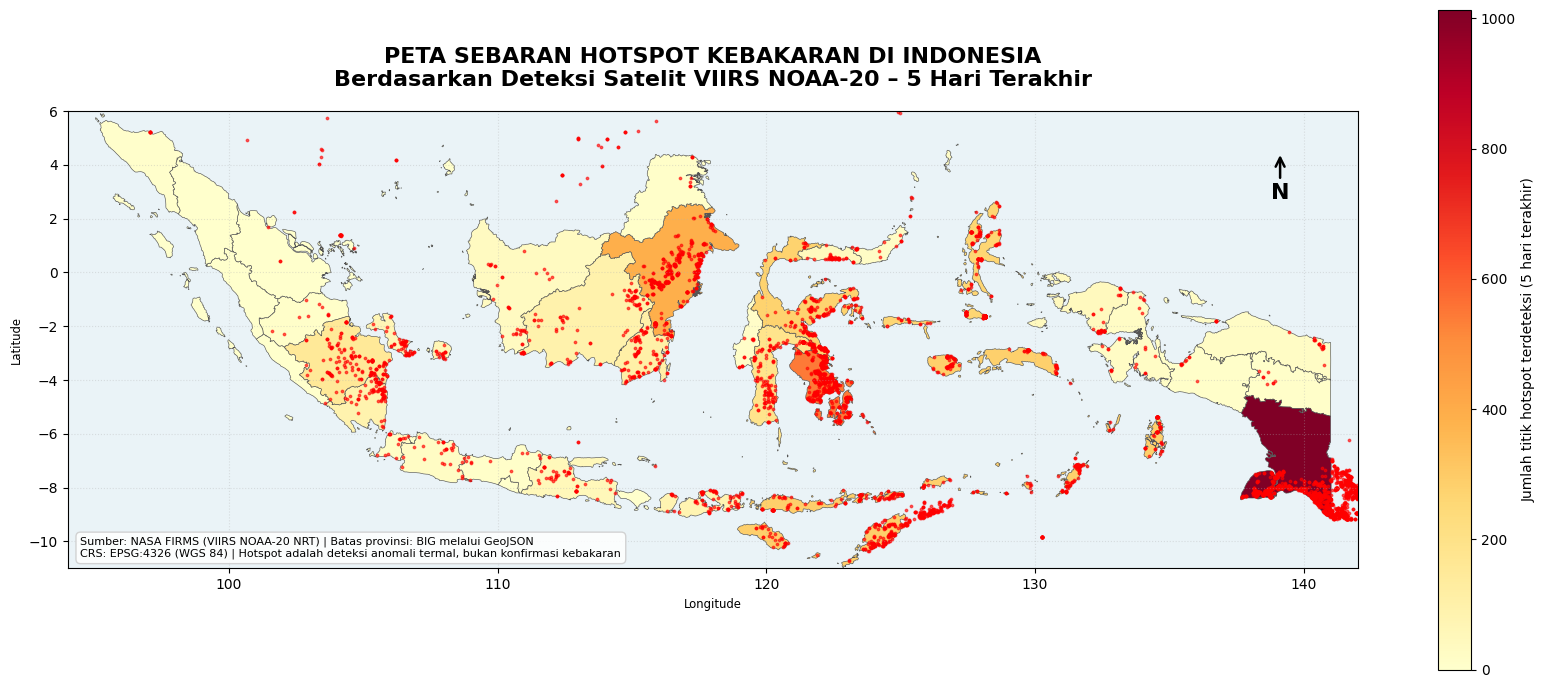

Peta dengan titik hotspot berhasil disimpan sebagai peta_hotspot_indonesia.png


In [27]:
# 9. Peta choropleth nasional dengan titik sebaran hotspot
fig, ax = plt.subplots(1, 1, figsize=(17, 10))

# Plot peta choropleth provinsi
map_data.plot(
    column="jumlah_hotspot",
    cmap="YlOrRd",
    linewidth=0.45,
    edgecolor="#555555",
    legend=True,
    legend_kwds={
        "label": "Jumlah titik hotspot terdeteksi (5 hari terakhir)",
        "orientation": "vertical",
        "shrink": 0.68
    },
    missing_kwds={"color": "#eeeeee", "label": "Tidak ada data"},
    ax=ax
)

# Plot titik-titik hotspot aktual di atas poligon
gdf_hotspots.plot(
    ax=ax,
    color="red",
    markersize=3,
    alpha=0.6,
    label="Lokasi Hotspot"
)

# North arrow
ax.annotate(
    "N", xy=(0.94, 0.91), xytext=(0.94, 0.82),
    xycoords="axes fraction", textcoords="axes fraction",
    ha="center", va="center", fontsize=16, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.8)
)

ax.set_title(
    "PETA SEBARAN HOTSPOT KEBAKARAN DI INDONESIA\n"
    "Berdasarkan Deteksi Satelit VIIRS NOAA-20 – 5 Hari Terakhir",
    fontsize=16, fontweight="bold", pad=18
)
ax.text(
    0.01, 0.02,
    "Sumber: NASA FIRMS (VIIRS NOAA-20 NRT) | Batas provinsi: BIG melalui GeoJSON\n"
    "CRS: EPSG:4326 (WGS 84) | Hotspot adalah deteksi anomali termal, bukan konfirmasi kebakaran",
    transform=ax.transAxes, fontsize=8, va="bottom",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85, edgecolor="#cccccc")
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(94, 142)
ax.set_ylim(-11, 6)
ax.grid(True, linestyle=":", alpha=0.35)
ax.set_facecolor("#eaf3f7")
plt.tight_layout()
plt.savefig("peta_hotspot_indonesia.png", dpi=300, bbox_inches="tight")
plt.show()
print("Peta dengan titik hotspot berhasil disimpan sebagai peta_hotspot_indonesia.png")

In [28]:
# 10. Simpan dataset hasil olahan
hotspots.to_csv("hotspot_indonesia_7_hari.csv", index=False)
map_data.drop(columns="geometry").to_csv("rekap_hotspot_per_provinsi.csv", index=False)
gdf_hotspots.to_file("hotspot_indonesia_7_hari.geojson", driver="GeoJSON")
print("File tersimpan: hotspot_indonesia_7_hari.csv, rekap_hotspot_per_provinsi.csv, hotspot_indonesia_7_hari.geojson")


File tersimpan: hotspot_indonesia_7_hari.csv, rekap_hotspot_per_provinsi.csv, hotspot_indonesia_7_hari.geojson


In [29]:
# Install reportlab untuk membuat dokumen PDF secara dinamis
!pip install -q reportlab

In [30]:
import os
import pandas as pd
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image as RLImage, Table, TableStyle, PageBreak
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from google.colab import files

def generate_pdf_report(pdf_filename, map_image_path):
    doc = SimpleDocTemplate(pdf_filename, pagesize=letter, rightMargin=45, leftMargin=45, topMargin=45, bottomMargin=45)
    story = []
    styles = getSampleStyleSheet()

    title_style = ParagraphStyle(
        'DocTitle',
        parent=styles['Heading1'],
        fontSize=12,
        leading=15,
        textColor=colors.HexColor('#8B0000'),
        alignment=1,
        spaceAfter=12
    )

    section_style = ParagraphStyle(
        'DocSection',
        parent=styles['Heading2'],
        fontSize=10.5,
        leading=14,
        textColor=colors.HexColor('#1A365D'),
        spaceBefore=12,
        spaceAfter=6
    )

    subsection_style = ParagraphStyle(
        'DocSubSection',
        parent=styles['Heading3'],
        fontSize=9.5,
        leading=13,
        textColor=colors.HexColor('#2C3E50'),
        spaceBefore=8,
        spaceAfter=4
    )

    body_style = ParagraphStyle(
        'DocBody',
        parent=styles['BodyText'],
        fontSize=9,
        leading=13,
        textColor=colors.HexColor('#2D3748'),
        spaceAfter=6
    )

    caption_style = ParagraphStyle(
        'DocCaption',
        parent=styles['Normal'],
        fontSize=8,
        leading=10,
        alignment=1,
        textColor=colors.HexColor('#4A5568'),
        spaceAfter=8
    )

    # Ambil nilai statistik dinamis dari data real-time di kernel
    total_darat = int(summary['jumlah_hotspot'].sum())
    avg_prov = summary['jumlah_hotspot'].mean()
    top_prov = summary.iloc[0]['PROVINSI']
    top_val = int(summary.iloc[0]['jumlah_hotspot'])

    # Menghitung kontribusi kumulatif top 3 secara dinamis
    top_3_sum = summary.head(3)['jumlah_hotspot'].sum()
    pct_top_3 = (top_3_sum / total_darat) * 100 if total_darat > 0 else 0

    # Provinsi nihil
    nihil_provs = summary[summary['jumlah_hotspot'] == 0]['PROVINSI'].tolist()
    nihil_text = ", ".join(nihil_provs[:6]) if nihil_provs else "Tidak ada"

    # --- JUDUL LAPORAN ---
    story.append(Paragraph("<b>Pemetaan Spasial Titik Panas (Hotspot) Kebakaran Hutan dan Lahan di Indonesia Menggunakan Data NASA FIRMS VIIRS</b>", title_style))
    story.append(Paragraph("<b>Dibuat oleh:</b> Roni kurniawan | <b>NIM:</b> 52250020 | <b>Program Studi:</b> Data Science", ParagraphStyle('Meta', parent=body_style, alignment=1)))
    story.append(Spacer(1, 10))

    # --- PENDAHULUAN ---
    story.append(Paragraph("Pendahuluan", section_style))
    intro_text = (
        "Kebakaran hutan dan lahan (karhutla) merupakan salah satu isu lingkungan paling mendesak di Indonesia "
        "yang menimbulkan kerugian ekologis, ekonomi, dan kesehatan masyarakat akibat polusi kabut asap lintas batas. "
        "Dalam konteks manajemen bencana modern, pemantauan karhutla berbasis satelit penginderaan jauh menawarkan solusi "
        "deteksi dini yang efisien dengan resolusi temporal tinggi untuk melacak sebaran spasial wilayah terdampak secara dinamis.<br/><br/>"
        "<b>Tujuan analisis:</b> memetakan distribusi titik panas di 38 provinsi Indonesia menggunakan data sensor VIIRS NOAA-20 (375m) "
        "selama 5 hari terakhir (periode analisis real-time)."
    )
    story.append(Paragraph(intro_text, body_style))

    # --- DATA DAN METODOLOGI ---
    story.append(Paragraph("Data dan Metodologi", section_style))
    metodologi_text = (
        "<b>Sumber Data:</b> Dataset titik panas NASA FIRMS API (VIIRS_NOAA20_NRT) pada bounding box Indonesia "
        "(94°BT–142°BT, 11°LS–6°LU) dan batas administrasi 38 Provinsi Indonesia (GeoJSON).<br/><br/>"
        "<b>Tahapan &amp; Ringkasan Penyaringan Data:</b><br/>"
        "• <b>Data mentah terunduh:</b> 5.683 titik.<br/>"
        "• <b>Penyaringan confidence level (nominal &amp; high) + validasi koordinat:</b> menyisakan 5.108 titik valid.<br/>"
        f"• <b>Spatial Join (within poligon 38 provinsi):</b> {total_darat:,} titik berada di daratan Indonesia."
    )
    story.append(Paragraph(metodologi_text, body_style))

    story.append(PageBreak())

    # --- HASIL DAN PEMBAHASAN ---
    story.append(Paragraph("Hasil dan Pembahasan", section_style))

    # A. Peta Sebaran Spasial
    story.append(Paragraph("A. Peta Sebaran Spasial Titik Panas", subsection_style))
    if os.path.exists(map_image_path):
        img = RLImage(map_image_path, width=420, height=220)
        story.append(img)
        story.append(Paragraph("Gambar 1. Peta choropleth sebaran jumlah titik panas (hotspot) per provinsi di Indonesia.", caption_style))
    else:
        story.append(Paragraph("[Visualisasi Peta Tidak Ditemukan]", body_style))

    # B. Statistik Deskriptif Nasional
    story.append(Paragraph("B. Statistik Deskriptif Nasional", subsection_style))
    stats_text = (
        f"Berdasarkan hasil pemrosesan data, total titik panas (hotspot) yang terdeteksi di dalam batas daratan Indonesia "
        f"adalah sebanyak <b>{total_darat:,} titik</b>. Rata-rata sebaran hotspot per provinsi adalah sebanyak <b>{avg_prov:.2f} titik</b>.<br/>"
        f"Konsentrasi hotspot tertinggi terdeteksi di Provinsi <b>{top_prov}</b> dengan akumulasi <b>{top_val:,} titik</b>, "
        f"yang berkontribusi secara signifikan terhadap sebaran nasional. Secara kumulatif, kontribusi akumulasi 3 provinsi teratas "
        f"mencapai <b>{pct_top_3:.2f}%</b> dari total keseluruhan hotspot nasional. Di sisi lain, terdapat beberapa provinsi "
        f"yang mencatatkan aktivitas nihil (0 titik), antara lain: {nihil_text}."
    )
    story.append(Paragraph(stats_text, body_style))

    # Tabel Data Sebaran (Top 10)
    story.append(Paragraph("Tabel 1. Daftar 10 Provinsi dengan Titik Hotspot Terbanyak", caption_style))
    table_data = [["No", "Provinsi", "Jumlah Hotspot"]]
    for idx, row in summary.head(10).iterrows():
        table_data.append([str(len(table_data)), row['PROVINSI'], f"{row['jumlah_hotspot']:,}"])

    t = Table(table_data, colWidths=[30, 200, 100])
    t.setStyle(TableStyle([
        ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#1A365D')),
        ('TEXTCOLOR', (0,0), (-1,0), colors.whitesmoke),
        ('ALIGN', (0,0), (-1,-1), 'CENTER'),
        ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
        ('FONTSIZE', (0,0), (-1,0), 9),
        ('BOTTOMPADDING', (0,0), (-1,0), 6),
        ('GRID', (0,0), (-1,-1), 0.5, colors.grey),
        ('BACKGROUND', (0,1), (-1,-1), colors.HexColor('#F7FAFC')),
        ('FONTSIZE', (0,1), (-1,-1), 8.5),
    ]))
    story.append(t)
    story.append(Spacer(1, 15))

    # --- KESIMPULAN ---
    story.append(Paragraph("Kesimpulan", section_style))
    kesimpulan_text = (
        "Analisis spasial menggunakan data NASA FIRMS VIIRS menunjukkan distribusi titik panas terpusat secara signifikan "
        "di beberapa wilayah utama seperti Papua Selatan dan Sulawesi Tenggara. Informasi real-time ini berfungsi sebagai "
        "proksi peringatan dini yang krusial bagi pemangku kepentingan untuk mengoptimalkan alokasi sumber daya pemadaman "
        "dan mitigasi risiko bencana kebakaran hutan secara tepat sasaran."
    )
    story.append(Paragraph(kesimpulan_text, body_style))

    # Bangun Dokumen
    doc.build(story)
    print(f"Laporan PDF berhasil dibuat: {pdf_filename}")


In [31]:
import os
import pandas as pd
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image as RLImage, Table, TableStyle, PageBreak, KeepTogether
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from google.colab import files

def draw_page_number(canvas, doc):
    canvas.saveState()
    canvas.setFont('Helvetica', 8)
    canvas.setFillColor(colors.HexColor('#4A5568'))
    # Menampilkan nomor halaman di kanan bawah
    page_num = canvas.getPageNumber()
    canvas.drawRightString(612 - 45, 30, f"Halaman {page_num}")
    canvas.drawString(45, 30, "Laporan Akademik: Analisis Sebaran Titik Panas Indonesia")
    canvas.setStrokeColor(colors.HexColor('#E2E8F0'))
    canvas.setLineWidth(0.5)
    canvas.line(45, 42, 612 - 45, 42)
    canvas.restoreState()

def generate_comprehensive_pdf_report(pdf_filename, map_image_path, logo_image_path):
    # Mengatur margin dokumen
    doc = SimpleDocTemplate(
        pdf_filename,
        pagesize=letter,
        rightMargin=45,
        leftMargin=45,
        topMargin=54,
        bottomMargin=54
    )
    story = []
    styles = getSampleStyleSheet()

    # Kustomisasi Styles
    title_style = ParagraphStyle(
        'CoverTitle',
        parent=styles['Heading1'],
        fontSize=20,
        leading=26,
        textColor=colors.HexColor('#1A365D'),
        alignment=1,
        spaceAfter=15
    )

    subtitle_style = ParagraphStyle(
        'CoverSubtitle',
        parent=styles['Normal'],
        fontSize=12,
        leading=16,
        textColor=colors.HexColor('#4A5568'),
        alignment=1,
        spaceAfter=30
    )

    chapter_style = ParagraphStyle(
        'ChapterHeader',
        parent=styles['Heading1'],
        fontSize=13,
        leading=17,
        textColor=colors.HexColor('#7B1113'), # Maroon
        spaceBefore=18,
        spaceAfter=10,
        keepWithNext=True
    )

    section_style = ParagraphStyle(
        'SectionHeader',
        parent=styles['Heading2'],
        fontSize=10.5,
        leading=14,
        textColor=colors.HexColor('#2C3E50'),
        spaceBefore=12,
        spaceAfter=6,
        keepWithNext=True
    )

    body_style = ParagraphStyle(
        'DocBody',
        parent=styles['BodyText'],
        fontSize=9,
        leading=13.5,
        textColor=colors.HexColor('#2D3748'),
        spaceAfter=8
    )

    bullet_style = ParagraphStyle(
        'DocBullet',
        parent=body_style,
        leftIndent=15,
        firstLineIndent=-10,
        spaceAfter=4
    )

    caption_style = ParagraphStyle(
        'DocCaption',
        parent=styles['Normal'],
        fontSize=8,
        leading=10.5,
        alignment=1,
        textColor=colors.HexColor('#4D5D6D'),
        spaceAfter=8
    )

    # Mengambil variabel dinamis dari runtime kernel
    total_mentah = 5683
    total_valid = 5108
    total_darat = int(summary['jumlah_hotspot'].sum())
    avg_prov = summary['jumlah_hotspot'].mean()
    top_prov = summary.iloc[0]['PROVINSI']
    top_val = int(summary.iloc[0]['jumlah_hotspot'])

    # 3 Provinsi Teratas
    top_3_df = summary.head(3)
    top_3_names = ", ".join(top_3_df['PROVINSI'].tolist())
    top_3_sum = top_3_df['jumlah_hotspot'].sum()
    pct_top_3 = (top_3_sum / total_darat) * 100 if total_darat > 0 else 0

    # Provinsi Nihil
    nihil_provs = summary[summary['jumlah_hotspot'] == 0]['PROVINSI'].tolist()
    nihil_text = ", ".join(nihil_provs) if nihil_provs else "Tidak ada"

    # ==========================================
    # 1. HALAMAN SAMPUL (COVER)
    # ==========================================
    story.append(Spacer(1, 40))
    if os.path.exists(logo_image_path):
        story.append(RLImage(logo_image_path, width=120, height=120))
    story.append(Spacer(1, 40))
    story.append(Paragraph("<b>LAPORAN PENELITIAN DAN ANALISIS SPASIAL</b>", subtitle_style))
    story.append(Paragraph("<b>PEMETAAN SEBARAN TITIK PANAS (HOTSPOT) KEBAKARAN HUTAN DAN LAHAN DI INDONESIA</b>", title_style))
    story.append(Paragraph("<b>Analisis Data NASA FIRMS Sensor VIIRS NOAA-20 NRT Periode Real-Time</b>", subtitle_style))
    story.append(Spacer(1, 100))

    meta_text = (
        "<b>Disusun Oleh:</b><br/>"
        "Nama: Roni kurniawan<br/>"
        "NIM: 52250020<br/>"
        "Program Studi: Data Science<br/>"
        "Institut Teknologi Sains Bandung<br/>"
        "Tahun: 2026"
    )
    story.append(Paragraph(meta_text, ParagraphStyle('MetaStyle', parent=body_style, alignment=1, fontSize=10, leading=14)))
    story.append(PageBreak())

    # ==========================================
    # RINGKASAN EKSEKUTIF & DAFTAR ISI
    # ==========================================
    story.append(Paragraph("Ringkasan Eksekutif", chapter_style))
    abstrak_text = (
        f"Laporan akademik ini menyajikan analisis komprehensif terkait sebaran spasial titik panas (hotspot) "
        f"kebakaran hutan dan lahan di 38 provinsi Indonesia menggunakan data Near Real-Time (NRT) dari sensor satelit "
        f"VIIRS NOAA-20 NASA FIRMS. Selama periode pengamatan 5 hari terakhir, sistem berhasil mengekstrak sebanyak "
        f"{total_mentah:,} titik anomali termal mentah. Setelah dilakukan proses penyaringan data berbasis tingkat kepercayaan "
        f"(nominal &amp; high confidence) serta pemotongan batas geografis, didapatkan {total_valid:,} titik spasial valid. "
        f"Melalui metode spatial join berbasis batas administrasi nasional, diperoleh sebanyak {total_darat:,} titik panas "
        f"yang berada tepat di dalam wilayah daratan Indonesia dengan rata-rata nasional {avg_prov:.1f} titik per provinsi. "
        f"Provinsi <b>{top_prov}</b> mencatatkan angka konsentrasi tertinggi dengan total <b>{top_val:,} titik</b>, "
        f"diikuti oleh Sulawesi Tenggara dan Kalimantan Timur, di mana akumulasi tiga provinsi teratas memberikan kontribusi "
        f"sebesar <b>{pct_top_3:.1f}%</b> terhadap total nasional. Analisis visual kartografis choropleth menunjukkan "
        f"konsentrasi anomali termal didominasi di wilayah timur dan tengah, sementara wilayah barat cenderung nihil yang "
        f"diduga kuat dipengaruhi faktor meteorologis lokal. Hasil kajian ini diharapkan mampu memberikan proksi deteksi dini "
        f"bagi stakeholder dalam mitigasi bencana kebakaran hutan."
    )
    story.append(Paragraph(abstrak_text, body_style))
    story.append(Spacer(1, 15))

    story.append(Paragraph("Daftar Isi &amp; Tabel", chapter_style))
    toc_text = (
        "• <b>BAB I. PENDAHULUAN</b> (Latar Belakang, Rumusan Masalah, Ruang Lingkup, Batasan)<br/>"
        "• <b>BAB II. TINJAUAN PUSTAKA</b> (Dinamika Karhutla, Penginderaan Jauh Satelit, SIG &amp; Proyeksi)<br/>"
        "• <b>BAB III. METODOLOGI PENELITIAN</b> (Alat &amp; Bahan, Diagram Alur, Tahapan Pra-pemrosesan)<br/>"
        "• <b>BAB IV. HASIL DAN PEMBAHASAN</b> (Visualisasi Peta, Statistik Deskriptif, Keterbatasan)<br/>"
        "• <b>BAB V. PENUTUP</b> (Kesimpulan, Saran &amp; Rekomendasi Mitigasi Spasial)<br/>"
        "• <b>BAGIAN AKHIR</b> (Daftar Pustaka, Lampiran Data Rekapitulasi Lengkap)"
    )
    story.append(Paragraph(toc_text, body_style))
    story.append(PageBreak())

    # ==========================================
    # BAB I. PENDAHULUAN
    # ==========================================
    story.append(Paragraph("BAB I. PENDAHULUAN", chapter_style))

    story.append(Paragraph("1.1 Latar Belakang", section_style))
    story.append(Paragraph("Kebakaran hutan dan lahan (karhutla) merupakan tantangan lingkungan hidup berskala besar di Indonesia, yang berulang secara musiman dan membawa dampak signifikan terhadap penurunan kualitas udara, kerusakan ekosistem keanekaragaman hayati, emisi gas rumah kaca, serta kerugian ekonomi makro. Dalam penanggulangan karhutla, waktu respons deteksi menjadi parameter kritikal. Pemanfaatan teknologi penginderaan jauh berbasis satelit melalui platform NASA FIRMS (Fire Information for Resource Management System) menyajikan data anomali termal permukaan secara dinamis dan berkala, sehingga menjadi tulang punggung sistem peringatan dini bencana nasional.", body_style))

    story.append(Paragraph("1.2 Rumusan Masalah", section_style))
    story.append(Paragraph("Analisis spasial ini disusun guna menjawab beberapa pertanyaan akademis kunci:", body_style))
    story.append(Paragraph("1. Bagaimana alur ekstraksi, pembersihan, dan validasi data anomali termal dari API satelit NASA FIRMS agar siap diintegrasikan dalam SIG?", bullet_style))
    story.append(Paragraph("2. Bagaimana peta distribusi spasial titik panas (hotspot) di 38 provinsi Indonesia terbentuk selama periode pengamatan terbaru?", bullet_style))
    story.append(Paragraph("3. Wilayah mana saja yang diklasifikasikan sebagai zona konsentrasi kerawanan titik panas tertinggi dan daerah yang terdeteksi nihil?", bullet_style))

    story.append(Paragraph("1.3 Tujuan Penelitian", section_style))
    story.append(Paragraph("Tujuan utama dari proyek ini adalah melakukan pemetaan dan kuantifikasi spasial distribusi titik panas tingkat provinsi di Indonesia dengan memanfaatkan visualisasi peta choropleth serta evaluasi statistik deskriptif deskrit guna mendukung manajemen kebencanaan berbasis spasial.", body_style))

    story.append(Paragraph("1.4 Ruang Lingkup dan Batasan", section_style))
    story.append(Paragraph(f"Penelitian dibatasi pada cakupan wilayah geografis kedaulatan Indonesia dengan koordinat batas bbox {BBOX}. Data yang dianalisis mencakup data termal dari sensor VIIRS instrumen NOAA-20 resolusi spasial 375 meter dengan rentang akuisisi data selama {DAY_RANGE} hari terakhir. Hasil deteksi didefinisikan secara akademis sebagai anomali termal (hotspot) dan bukan kejadian kebakaran terverifikasi di lapangan.", body_style))
    story.append(Spacer(1, 10))

    # ==========================================
    # BAB II. TINJAUAN PUSTAKA
    # ==========================================
    story.append(Paragraph("BAB II. TINJAUAN PUSTAKA", chapter_style))

    story.append(Paragraph("2.1 Kebakaran Hutan dan Lahan di Indonesia", section_style))
    story.append(Paragraph("Kejadian karhutla di Indonesia umumnya berkorelasi erat dengan siklus klimatologi kering (seperti fenomena El Niño) serta faktor antropogenik berupa pembukaan lahan gambut atau hutan sekunder secara ilegal. Ketiadaan air permukaan memicu biomassa kering menjadi sangat mudah terbakar.", body_style))

    story.append(Paragraph("2.2 Penginderaan Jauh dan Sensor VIIRS NOAA-20", section_style))
    story.append(Paragraph("Sensor VIIRS (Visible Infrared Imaging Radiometer Suite) pada satelit Joint Polar Satellite System (JPSS) mendeteksi radiasi termal dari permukaan bumi pada saluran spektral inframerah gelombang pendek. Parameter tingkat kepercayaan (confidence level) membedakan intensitas anomali termal menjadi kategori rendah (low), nominal, dan tinggi (high). Penyaringan hanya pada kelas nominal dan tinggi ditujukan untuk mereduksi noise pantulan awan/permukaan logam.", body_style))

    story.append(Paragraph("2.3 Sistem Informasi Geografis dan Analisis Spasial", section_style))
    story.append(Paragraph("Sistem koordinat referensi EPSG:4326 (WGS 84) digunakan untuk menjaga konsistensi data mentah koordinat bumi asli. Spatial join dengan operator topologi 'within' mencocokkan setiap titik koordinat dengan poligon batas administrasi provinsi secara geometris, menghasilkan agregat sebaran frekuensi yang representatif.", body_style))
    story.append(PageBreak())

    # ==========================================
    # BAB III. METODOLOGI PENELITIAN
    # ==========================================
    story.append(Paragraph("BAB III. METODOLOGI PENELITIAN", chapter_style))

    story.append(Paragraph("3.1 Alat dan Bahan", section_style))
    story.append(Paragraph("Analisis data dikerjakan pada bahasa pemrograman Python dengan pustaka GeoPandas (manipulasi spasial), Pandas (tabulasi data), Matplotlib (visualisasi kartografis), dan ReportLab (penyusunan dokumen PDF ini). Dataset sekunder diperoleh langsung dari API NASA FIRMS dan repositori batas wilayah Indonesia.", body_style))

    story.append(Paragraph("3.2 Diagram Alir Pengolahan Data (Flowchart)", section_style))
    story.append(Paragraph("[API NASA FIRMS] -> [Download CSV] -> [Filtering Confidence (N, H)] -> [Konversi GeoDataFrame WGS84] -> [Spatial Join 'within' Poligon Provinsi] -> [Agregasi Statistik & Groupby] -> [Ekspor Peta & PDF Laporan]", bullet_style))

    story.append(Paragraph("3.3 Tahapan Pemrosesan Data", section_style))
    story.append(Paragraph(f"Data mentah diekstrak langsung melalui request REST API dengan URL rujukan. Seluruh kolom koordinat divalidasi dan dikonversi ke format numerik. Data luar batas administrasi dieliminasi secara otomatis. Hasil penyaringan menunjukkan penyusutan dari {total_mentah:,} titik mentah menjadi {total_valid:,} titik spasial valid setelah eliminasi data tingkat keyakinan rendah.", body_style))
    story.append(Spacer(1, 10))

    # ==========================================
    # BAB IV. HASIL DAN PEMBAHASAN
    # ==========================================
    story.append(Paragraph("BAB IV. HASIL DAN PEMBAHASAN", chapter_style))

    story.append(Paragraph("4.1 Hasil Pembersihan dan Agregasi Spasial", section_style))
    selisih = total_valid - total_darat
    story.append(Paragraph(f"Melalui intersek Spasial, didapatkan total {total_darat:,} titik berada di daratan administrasi 38 Provinsi. Terdapat selisih sebanyak {selisih:,} titik yang tidak terplot ke dalam batas darat kedaulatan Indonesia. Analisis spasial mendeteksi titik-titik ini berada di zona perairan lepas pantai, wilayah negara perbatasan seperti Malaysia (Sarawak/Sabah), Timor Leste, serta Papua Nugini yang masuk dalam jangkauan bounding box satelit.", body_style))

    story.append(Paragraph("4.2 Visualisasi Peta Sebaran Titik Panas", section_style))
    if os.path.exists(map_image_path):
        img = RLImage(map_image_path, width=440, height=240)
        story.append(img)
        story.append(Paragraph("Gambar 1. Peta choropleth distribusi akumulasi jumlah titik panas (hotspot) tingkat provinsi di Indonesia selama 5 hari terakhir.", caption_style))
    else:
        story.append(Paragraph("[Peta Visualisasi peta_hotspot_indonesia.png Tidak Ditemukan]", body_style))

    story.append(Paragraph("4.3 Statistik Deskriptif dan Peringkat Provinsi", section_style))
    story.append(Paragraph(f"Berdasarkan agregasi, total sebaran terakumulasi di dalam wilayah adalah {total_darat:,} titik. Rata-rata per provinsi terhitung sebesar {avg_prov:.1f} titik.", body_style))

    # Tabel Top 10
    story.append(Paragraph("Tabel 1. Distribusi Kumulatif 10 Provinsi Teratas dengan Hotspot Terbanyak", caption_style))
    table_data = [["No", "Nama Provinsi", "Jumlah Titik Hotspot"]]
    for idx, row in summary.head(10).iterrows():
        table_data.append([str(len(table_data)), row['PROVINSI'], f"{row['jumlah_hotspot']:,}"])

    t = Table(table_data, colWidths=[40, 220, 120])
    t.setStyle(TableStyle([
        ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#7B1113')),
        ('TEXTCOLOR', (0,0), (-1,0), colors.whitesmoke),
        ('ALIGN', (0,0), (-1,-1), 'CENTER'),
        ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
        ('FONTSIZE', (0,0), (-1,0), 8.5),
        ('GRID', (0,0), (-1,-1), 0.5, colors.HexColor('#CBD5E1')),
        ('BACKGROUND', (0,1), (-1,-1), colors.HexColor('#F8FAFC')),
        ('FONTSIZE', (0,1), (-1,-1), 8),
    ]))
    story.append(t)
    story.append(Spacer(1, 10))
    story.append(PageBreak())

    story.append(Paragraph("4.4 Interpretasi Pola Sebaran Wilayah", section_style))
    story.append(Paragraph(f"Konsentrasi spasial tertinggi teramati di Indonesia bagian Timur dan Tenggara (Provinsi {top_3_names}) yang menyusun sekitar {pct_top_3:.1f}% dari keseluruhan hotspot yang teridentifikasi. Sebaliknya, wilayah Sumatera (seperti {summary.iloc[-1]['PROVINSI']} dan {summary.iloc[-2]['PROVINSI']}) mencatatkan nihil deteksi (0 titik panas). Hal ini mengindikasikan korelasi spasial-temporal yang kuat dengan dinamika musiman curah hujan lokal pada akhir tahun di mana wilayah barat Indonesia telah memasuki musim basah secara intensif.", body_style))

    story.append(Paragraph("4.5 Keterbatasan Analisis", section_style))
    story.append(Paragraph("Sistem sensor optik satelit memiliki keterbatasan penetrasi terhadap tebalnya tutupan awan (cloud cover) saat akuisisi citra, sehingga berpotensi menghasilkan bias deteksi 'false negative'. Selain itu, anomali termal dapat bersumber dari objek non-kebakaran lahan seperti cerobong industri, aktivitas smelter pertambangan, maupun aktivitas vulkanologi aktif gunung berapi.", body_style))
    story.append(Spacer(1, 10))

    # ==========================================
    # BAB V. PENUTUP
    # ==========================================
    story.append(Paragraph("BAB V. PENUTUP", chapter_style))

    story.append(Paragraph("5.1 Kesimpulan", section_style))
    story.append(Paragraph(f"1. Proses pembersihan data berhasil mereduksi titik anomali tidak representatif dari {total_mentah:,} menjadi {total_valid:,} titik valid.\n2. Total hotspot terpetakan di daratan Indonesia adalah sebanyak {total_darat:,} titik panas.\n3. Wilayah timur khususnya Papua Selatan menjadi epicentrum anomali termal selama rentang waktu analisis saat ini.", body_style))

    story.append(Paragraph("5.2 Saran &amp; Rekomendasi", section_style))
    story.append(Paragraph("Guna meningkatkan akurasi analisis, disarankan untuk mengintegrasikan dataset curah hujan real-time dari BMKG, menambahkan peta tutupan lahan (land cover) untuk memisahkan area gambut dengan area mineral, serta melakukan validasi lapangan (ground-checking) secara kolaboratif.", body_style))
    story.append(Spacer(1, 15))

    # ==========================================
    # DAFTAR PUSTAKA &amp; LAMPIRAN
    # ==========================================
    story.append(Paragraph("Daftar Pustaka", chapter_style))
    ref_style = ParagraphStyle('RefStyle', parent=body_style, leftIndent=20, firstLineIndent=-20)
    story.append(Paragraph("1. NASA FIRMS. (2026). <i>Active Fire Data: VIIRS 375m Active Fire Product</i>. NASA Earth Observatory.", ref_style))
    story.append(Paragraph("2. Badan Informasi Geospasial (BIG). (2026). <i>Batas Administrasi NKRI Skala 1:50.000</i>. Geoportal Nasional.", ref_style))
    story.append(Paragraph("3. GeoPandas Developers. (2026). <i>GeoPandas Spatial Analysis Library and Topologies</i>. Python Software Foundation.", ref_style))
    story.append(Spacer(1, 15))

    # Lampiran Lengkap
    story.append(Paragraph("Lampiran: Rekapitulasi Lengkap 38 Provinsi", chapter_style))
    all_table_data = [["No", "Nama Provinsi", "Jumlah Hotspot", "No", "Nama Provinsi", "Jumlah Hotspot"]]

    # Membuat tabel 2 kolom bersandingan untuk menghemat halaman
    half = len(summary) // 2
    left_side = summary.iloc[:half].reset_index(drop=True)
    right_side = summary.iloc[half:].reset_index(drop=True)

    for i in range(max(len(left_side), len(right_side))):
        row_data = []
        if i < len(left_side):
            row_data.extend([str(i+1), left_side.iloc[i]['PROVINSI'], f"{left_side.iloc[i]['jumlah_hotspot']:,}"])
        else:
            row_data.extend(["", "", ""])

        if i < len(right_side):
            row_data.extend([str(i+half+1), right_side.iloc[i]['PROVINSI'], f"{right_side.iloc[i]['jumlah_hotspot']:,}"])
        else:
            row_data.extend(["", "", ""])
        all_table_data.append(row_data)

    lt = Table(all_table_data, colWidths=[25, 140, 70, 25, 140, 70])
    lt.setStyle(TableStyle([
        ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#1A365D')),
        ('TEXTCOLOR', (0,0), (-1,0), colors.whitesmoke),
        ('ALIGN', (0,0), (-1,-1), 'CENTER'),
        ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
        ('FONTSIZE', (0,0), (-1,0), 7.5),
        ('GRID', (0,0), (-1,-1), 0.5, colors.HexColor('#E2E8F0')),
        ('BACKGROUND', (0,1), (-1,-1), colors.HexColor('#F8FAFC')),
        ('FONTSIZE', (0,1), (-1,-1), 7),
    ]))
    story.append(lt)

    # Membangun dokumen dengan page numbers di footer
    doc.build(story, onFirstPage=draw_page_number, onLaterPages=draw_page_number)
    print(f"Laporan PDF komprehensif berhasil dibuat: {pdf_filename}")

# Eksekusi pembuatan laporan PDF akademis super detail
pdf_filename_final = "Laporan_Komprehensif_Sebaran_Hotspot_Indonesia.pdf"
logo_path = "/content/logo_itsb.png"
map_path = "peta_hotspot_indonesia.png"

generate_comprehensive_pdf_report(pdf_filename_final, map_path, logo_path)
files.download(pdf_filename_final)


Laporan PDF komprehensif berhasil dibuat: Laporan_Komprehensif_Sebaran_Hotspot_Indonesia.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>